# Trabajo Práctico  - Calibración y Pose de la Cámara

## Resolución

## GRUPO: MEDJ

# Integrantes
* Matías Agustín Tabak Wolf (273/24)
* Elking Richelieu Mendoza Zambrano (118/25)
* Dante Fongi Martínez (799/24)

In [1]:
import alc
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import cv2

### Ejercicio 1 - DLT ecuaciones formales

Armado de la matriz $Q$ para la imagen 1

In [3]:
#Obtenemos las rutas de los archivos para luego hacer la lectura de los mismos
detected_corners_path = os.path.join('calib','3d','detected_corners.txt')
p_W_corners_path = os.path.join('calib','3d','p_W_corners.txt')

corners = np.loadtxt(p_W_corners_path,delimiter=',')

#Definimos a las variables U, V y W que guardan la primer, segunda y tercer columna, respectivamente, del archivo de los puntos del mundo real. Esto quiere decir que U es un array que contiene únicamente la primer coordenada de todos los puntos del archivo p_W_corners.txt (análogamente sucede lo mismo con V y W pero con la segunda y tercer coordenada de los puntos).
U, V, W = corners[:,0], corners[:,1], corners[:,2]

#Definimos en una variable G el contenido del archivo detected_corners.txt
G = np.loadtxt(detected_corners_path)

#Definimos la matriz Q como un array de ceros, con las dimensiones correspondientes, que luego completaremos en cada iteración
Q = np.zeros((2*corners.shape[0],12))
i = 0 #Definimos a en base a que foto construiremos nuestra Q, en este caso será la primer foto.
for j in range(corners.shape[0]): #Iteramos por cada punto en el mundo real y construimos la matriz Q tal como indica la ecuación (6)
    u = G[i][2*j] #Representa la primer coordenada asociada a la j-esimo punto del mundo real en la i-esima foto
    v = G[i][2*j+1] #Representa la segunda coordenada asociada a la j-esimo punto del mundo real en la i-esima foto

    #Escribimos cada par de filas asociadas a cada coordenada del mundo real
    Q[2*j, :] =     [U[j], V[j], W[j], 1,   0,    0,    0,   0, -u*U[j], -u*V[j], -u*W[j], -u]
    Q[2*j + 1, :] = [ 0,    0,    0,   0,  U[j], V[j], W[j], 1, -v*U[j], -v*V[j], -v*W[j], -v]

La matriz $Q$ de la imagen 1 es

In [ ]:
print(Q)

[[ 0.0000000e+00  8.0000000e+00  0.0000000e+00  1.0000000e+00
   0.0000000e+00  0.0000000e+00  0.0000000e+00  0.0000000e+00
  -0.0000000e+00 -1.4920000e+03 -0.0000000e+00 -1.8650000e+02]
 [ 0.0000000e+00  0.0000000e+00  0.0000000e+00  0.0000000e+00
   0.0000000e+00  8.0000000e+00  0.0000000e+00  1.0000000e+00
  -0.0000000e+00 -1.5000000e+03 -0.0000000e+00 -1.8750000e+02]
 [ 1.0400000e+01  8.0000000e+00  0.0000000e+00  1.0000000e+00
   0.0000000e+00  0.0000000e+00  0.0000000e+00  0.0000000e+00
  -2.7508000e+03 -2.1160000e+03 -0.0000000e+00 -2.6450000e+02]
 [ 0.0000000e+00  0.0000000e+00  0.0000000e+00  0.0000000e+00
   1.0400000e+01  8.0000000e+00  0.0000000e+00  1.0000000e+00
  -1.7316000e+03 -1.3320000e+03 -0.0000000e+00 -1.6650000e+02]
 [ 0.0000000e+00  2.1500000e+01  0.0000000e+00  1.0000000e+00
   0.0000000e+00  0.0000000e+00  0.0000000e+00  0.0000000e+00
  -0.0000000e+00 -4.6977500e+03 -0.0000000e+00 -2.1850000e+02]
 [ 0.0000000e+00  0.0000000e+00  0.0000000e+00  0.0000000e+00
   

Sus valores singulares son

In [ ]:
matrizU, valoresSingulares, matrizV = alc.svd_reducida(Q) 
print(valoresSingulares)

[4.97789854e+04 1.34282938e+04 1.11901112e+04 3.41445598e+02
 9.40027039e+01 3.07710853e+01 2.40774842e+01 6.46959324e+00
 4.93930228e+00 2.09892503e+00 8.97869553e-01 8.22274505e-03]


El menor valor singular se corresponde al ubicado en la última posición de la diagonal de la matriz $\Sigma$ de una descomposición SVD, o sea el ubicado en la posición $(\min\{m,n\}, \min\{m,n\})$ (siendo $m$ la cantidad de filas y $n$ la cantidad de columnas de la matriz).

En el caso del output de nuestra función svd_reducida del módulo alc, que no devuelve los valores singulares en una matriz sino en un array, se corresponde al último valor del array valoresSingulares (puesto que estan ordenados de manera decreciente), el cual es

In [ ]:
print(valoresSingulares[-1])

0.00822274505147498


Dado que el vector $m$ es el asociado al valor singular más pequeño entonces el mismo se corresponde a la última columna de la matriz $V$ (la demostración de lo dicho se encuentra en la celda de texto siguiente). Por lo que la norma $\|Qm\|$ es igual a

In [ ]:
m = matrizV[:,-1]
Qm = alc.arroba(Q,m)
print(alc.norma(Qm,2))

0.008222745610321183


Siendo $Q\in \mathbb{R}^{2n\times 12}$, ¿qué rango debe tener para asegurar una solución no nula única a menos de un factor de escala? ¿Cuántos puntos, como mínimo, aseguran la solución y qué condición deben cumplir?

Encontrar el vector $\mathbf{m}$ que resuelve la minimización de la ecuación 6.

<u>**Primer pregunta**</u>

Para responderla recurrimos al siguiente teorema:

* **Teorema de Rango-Nulidad** $\longrightarrow$ Sean $V$ y $W$ espacios vectoriales con $dim(V) < +\infty$ y sea $T:V \longrightarrow W$ una transformación lineal entonces $dim(Im(T)) + dim(Nu(T)) = dim(V)$

Considerando que debemos asegurar que hay una solución no nula única a menos de un factor de escala (esto último no interfiere en la consideración del teorema y respuesta del enunciado ya que el conjunto de soluciones es un subespacio y por lo tanto considera a todos sus múltiplos, con hallar una es suficiente y mantiene la propiedad de ser única), sabemos entonces que la $dim(Nu(\mathbf{Q})) = 1$, luego por el teorema podemos despejar $dim(Im(\mathbf{Q}))$, que es quien responde a la pregunta del rango. Por lo mencionado, podemos decir que $dim(Im(\mathbf{Q})) = dim(V) - dim(Nu(\mathbf{Q})) = dim(V) - 1 = 12 - 1 = 11$. El rango que debe tener $\mathbf{Q}$ para asegurar una solución no nula única a menos de un factor de escala es 11.

¿Quien es $V$? ¿Por qué $dim(V) = 12$? Podemos definir a $T$, la transformación lineal que representa nuestra matriz $\mathbf{Q}$, tal que (por las dimensiones de $\mathbf{Q}$) vemos que toma elementos de $\mathbb{R}^{12}$ y los lleva a $\mathbb{R}^{2n}$, siendo entonces $T:\mathbb{R}^{12} \longrightarrow \mathbb{R}^{2n}$. Por ello, el espacio de salida es $V = \mathbb{R}^{12}$ y $dim(R^{12}) = 12$ $\Longrightarrow$ $dim(V) = 12$.

<u>**Segunda pregunta**</u>

¿Cuántos puntos, como mínimo, aseguran la solución? Prestando atención a esta parte de la pregunta vemos que la misma también se traduce a cuantas filas necesitamos como mínimo para que la respuesta de la anterior pregunta sea válida (o sea, $dim(Im(\mathbf{Q})) = 11$ y, por lo tanto, $dim(Nu(\mathbf{Q})) = 1$) ¿Por qué filas si nos preguntan puntos? Porque cada par de filas en la matriz $\mathbf{Q}$ representa un punto, y además sabemos que el rango de una matriz (que es igual a la dimensión de la imagen de la matriz) es mayor o igual a uno y menor o igual a la cantidad de filas de ella. Por lo que podemos concluir que $dim(Im(\mathbf{Q})) = 11 \leq 2n$, más específicamente: $\frac{11}{2} = 5.5 \leq n$. Entonces (considerando que $n$ es un número natural) la cantidad de puntos mínimos que aseguran la solución son $6$. 

¿Y qué condición deben cumplir? Como $dim(Im(\mathbf{Q})) = 11$ entonces sabemos que las filas deben de ser linealmente independientes entre sí, ya que le hallamos un techo al decir que $n = 6$ por lo menos, pero también debemos garantizar su piso para que la dimensión del núcleo no crezca (ya que de esa manera perderiamos la condición $dim(Nu(\mathbf{Q})) = 1$ y sería mayor a uno). Para ello, la matriz $\mathbf{Q}$ es una matriz que tiene 11 filas necesariamente linealmente independientes. Traduciendo esa información a los puntos $U,V,W$ logramos entender que será necesario que hayan 6 puntos no coplanares, o sea que hayan 6 puntos distribuidos de tal manera que no exista un plano que pueda contenerlos a la vez.

<u>**Hallar el vector**</u> $\mathbf{m}$

Sea $Q$ una matriz de $\mathbb{R}^{m \times n}$ tal que, por su descomposición SVD, podemos decir que $Q = U \Sigma V^t$, con $U \in \mathbb{R}^{m \times m}$, $\Sigma \in \mathbb{R}^{m \times n}$ y $V \in \mathbb{R}^{n \times n}$. Siendo $U$ y $V$ ortogonales.

Donde la matriz $V$ son los autovectores asociados a los autovalores de la matriz $Q^t Q$ escritos a modo de columnas, en orden asociado a los valores singulares dados en la matriz $\Sigma$ y forman una base ortonormal ($BON$); la matriz $\Sigma$ es una matriz que contiene en la diagonal dada desde la posición $(1,1)$ hasta $(\min\{m,n\}, \min\{m,n\})$ los valores singulares de $Q$ de forma decreciente (o sea, $\sigma_i = \sqrt{\lambda_i}$, siendo $\lambda_i$ los autovalores de la matriz $Q^t Q$), y en el resto de sus posiciones hay solamente ceros; y la matriz $U$ está dada por los vectores $u_i  = \frac{Q v_i}{\sigma_i}$ a modo de columna (siendo dicha igualdad para cuando $\sigma_i \neq 0$), luego en caso de haber valores singulares nulos o que $m > n$ se obtienen el resto de vectores extendiendo a una base ortonormal.

Dado que por enunciado queremos hallar el vector $\mathbf{m}$ tal que minimice la siguiente expresión

$$\min\limits_{\mathbf{m}} \|\mathbf{Qm}\|^2$$

Podemos decir que, por la descomposición SVD explicada al inicio del texto, es igual a hallar el $\mathbf{m}$ que minimice la expresión dada con la matriz $Q$ escrita como multiplicación de $U$, $\Sigma$ y $V^t$.

$$\min\limits_{\mathbf{m}} \|\mathbf{Qm}\|^2 = \min\limits_{\mathbf{m}} \|U \Sigma V^t m\|^2$$

Puesto que $U$ y $V^t$ son ortogonales, pues si $V$ es ortogonal entonces $V^t$ es ortogonal también, sabemos que $\|\mathbf{Ux}\| = \|\mathbf{x}\|$ $\forall x \in \mathbb{R^m}$ y $\|\mathbf{V^tx}\| = \|\mathbf{x}\| \, \forall x \in \mathbb{R^n}$, por lo que podemos reescribir la anterior expresión de la siguiente manera

$$\min\limits_{\mathbf{m}} \|\Sigma V^t m\|^2$$

Esta paso es valido pues la multiplicación $\Sigma V^t m$ devuelve un vector, y como $U$ es ortogonal podemos garantizar que $\| U \Sigma V^t m\| = \| U (\Sigma V^t m)\| = \|\Sigma V^t m\|$

Para resolver la minimización podemos decir que $\Sigma V^t m$ = $\Sigma (V^t m)$ = $\Sigma y$ con $y$ vector tal que $y = V^t m$. Esta reescritura nos es útil y la elegimos ya que podemos concluir que $\|y\| = \|V^t m\| = \|m\| = 1$ pues $V^t$ es ortogonal y, por definición de la ecuación $(7)$, $\|m\| = 1$. Entonces lo anterior es igual a la siguiente expresión

$$\min\limits_{\mathbf{y}} \|\Sigma y\|^2$$


Lo que nos interesa ahora es hallar un vector unitario $y$ tal que el mismo minimiza la expresión. Desarrollamos la norma al cuadrado de la minimización y vemos que

$$\|\Sigma y\|^2 = \displaystyle\sum_{i=1}^{n} (\sigma_i y_i)^2 = \displaystyle\sum_{i=1}^{n} \sigma_i^2 y_i^2$$

Dado que los valores singulares se encuentran ordenados de forma decreciente (o sea, $\sigma_1 \ge \sigma_2 \ge ... \ge \sigma_n \ge 0$) entonces podemos garantizar que $\sigma_i \ge \sigma_n \, \forall i = 1,...,n$. Valiendo también $\sigma_i^2 \ge \sigma_n^2 \, \forall i = 1,...,n$. Teniendo dicha desigualdad podemos acotar la expresión desarrollada de la siguiente forma

$$\|\Sigma y\|^2 = \displaystyle\sum_{i=1}^{n} \sigma_i^2 y_i^2 \ge \displaystyle\sum_{i=1}^{n} \sigma_n^2 y_i^2 = \sigma_n^2 \displaystyle\sum_{i=1}^{n} y_i^2 = \sigma_n^2 \|y\|^2 = \sigma_n^2 * 1 = \sigma_n^2$$

(La suma se realiza hasta $n$ y no $m$ pues en el caso de nuestra $Q$ tenemos que $m \ge n$ y el vector resultante es un vector con ceros luego de la $n$-esima posición si $m > n$, por lo que realizar la suma hasta $n$ en vez de $m$ es igual de válido).

De esta manera logramos acotar inferiormente la minimización y podemos indicar que la misma se obtiene cuando $y = e_n$, puesto que $\|e_n\| = 1$ y $\Sigma e_n = (0,...,0,\sigma_n,0,...,0)^t$. Entonces

$$\|\Sigma e_n\|^2 = \|(0,...,0,\sigma_n,0,...,0)^t\|^2 = \sigma_n^2$$

Reacomodando la reescritura que dimos para facilitar la demostración vemos que $y = e_n = V^t m$. Puesto que $V^t$ es ortogonal, vemos que  $Ve_n = m$ y $Ve_n = v_n = m$ (siendo $v_n$ la $n$-ésima columna de $V$, y como $V$ es ortogonal y sus columnas forman una $BON$ entonces vale que $\|v_n\| = 1$).

$\therefore$ El vector $m$ que minimiza la expresión $\|\mathbf{Qm}\|^2$ es $m = v_n$.

### Ejercicio 2 - Calibración con puntos 3D

a) Utilizando los datos de la carpeta $\texttt{calib/3d}$ calcular $\mathbf{R}$,  $\mathbf{t}$ y $\mathbf{K}$.

La idea principal detras del código es que estamos aplicando el concepto de calibración de cámara mediante el método DLT propuesto por Tsai. En sencillas palabras dicho método requiere de tomar las coordenadas de puntos del mundo real, las coordenadas en pixeles de dichos puntos del mundo real pero en la imagen y obtener así las variables extrínsecas ($R$ y $t$), que definen la pose de la cámara, y parámetros instrínsecos ($K$) de la cámara. Para llegar a ese resultado desarrollamos las funciones:
- obtenerQ3d $\longrightarrow$ toma dos inputs, las coordenadas de los puntos en la imagen y las coordenadas de los puntos en el mundo real. Interpreta que el ingreso de esos datos está dado por arrays donde cada fila representa un punto y sus columnas son cada coordenada. Cada fila del primer parámetro está asociada a cada fila del segundo parámetro. La función itera sobre el input dado y devuelve la matriz $Q$ del sistema homogéneo planteado por DLT ($Qm = 0$).
- resolverDLT3D $\longrightarrow$ toma como input la matriz $Q$ devuelta por la función obtenerQ3d y lo que hace es realizar la descomposición SVD para tomar la última columna de la matriz $V$ (fundamentado en el ejercicio 1 de este archivo .ipynb), luego aplica un reshape para devolver la información a modo de matriz y no vectorizado. Por lo que su output es una matriz $M$ que contiene la información de $K$, $R$ y $t$, aunque no explicita.
- devolverMatricesCalibracion3d $\longrightarrow$ toma la matriz $M$ devuelta por la función resolverDLT3D y devuelve $R$, $t$ y $K$. El proceso por el cual logra ir de $M$ (que es igual a $K[R | t]$) a $R$, $t$ y $K$ es pensar a la matriz $M$ en bloques tal que $M = K[R | t] = [KR | Kt] = [A | b]$. Al tomar $A = KR$ y $b = Kt$ logramos pautar una igualdad estratégica para despejar a las matrices deseadas.

(Desarrollando con más detalle devolverMatricesCalibracion3d)

Con la matriz $M$ pensada en bloques no es suficiente ya que tenemos las matrices que nos interesan pero el orden en el que están no permiten hallar de forma directa su valor. Por ello reacomodamos las expresiones con su traspuesta y una matriz de permutación tal que queden igualadas a su descomposición $QR$ (una matriz ortogonal y una matriz triangular superior).


El siguiente paso es definir la matriz de permutación, en este caso $P = \begin{pmatrix} 0 & 0 & 1 \\ 0 & 1 & 0 \\ 1 & 0 & 0 \end{pmatrix}$. Que al multiplicar por izquierda invierte las filas y a derecha las columnas. Otro punto importante de $P$ es que es simétrica y su inversa es ella misma, o sea $P = P^t = P^{-1}$.

El proceso es el siguiente:
1) Trasponemos a $A = KR \longrightarrow A^t = R^t K^t$
2) Multiplicamos a $A^t$ por $P$ a izquierda y derecha $\longrightarrow P A^t P = P R^t K^t P$. Además, como $P$ es su propia inversa, $P A^t P = P R^t K^t P = P R^t (P P) K^t P$
3) Descomponemos en una factorización $QR$ a la matriz (escribiremos en minúscula la desomposición, o sea $qr$, para no confundir con la $R$ de la calibración). Por lo que $P A^t P = qr = P R^t (PP) K^t P = (P R^t P)(P K^t P)$
4) Vemos que $qr = (P R^t P)(P K^t P)$ y por lo tanto consideramos $q = (P R^t P)$ y $r = (P K^t P)$. Luego podemos multiplicar a $P$ por izquierda y derecha de cada igualdad y trasponer, obteniendo así $R = P q^t P$ y $K = P r^t P$
5) Para cada elemento de la diagonal de $K$ nos aseguramos que su signo sea positivo, si alguno de esos elementos es negativo entonces a esa columna de $K$ la multiplicamos por $-1$ y realizamos lo mismo en $R$ pero para su fila correspondiente (esto debido a cómo funciona la multiplicación matricial, los signos se cancelan, no se rompe la ortogonalidad de $R$, y de esta manera logramos dar un resultado válido). Esto se debe a que los elementos de la diagonal de $K$ refieren a las distancias focales en píxeles y el factor de escala, que por trabajar en el mundo físico real, para que el resultado tenga sentido, debe ser positivo.
6) Como definimos $b = Kt$, y queremos calcular $t$, entonces multiplicamos por la inversa de $K$ a izquierda de ambos lados de la igualdad y obtenemos $K^{-1} b = t$
7) Nos aseguramos que el determinante de $R$ sea positivo, y en caso de no serlo multiplicamos a $R$ y $t$ por $-1$. Como $R$ es ortogonal, entonces $|det(R)| = 1$, pero al trabajar en el mundo físico un determinante negativo no tiene sentido ya que nos habla de un efecto de la cámara que no es aplicable en el mundo real. En caso de tener un determinante negativo, multiplicar a $R$ por $-1$ es válido pues mantiene su ortogonalidad ya que $det(-R) = (-1)^3 det(R) = (-1) * (-1) = 1$. A su vez, es necesario multiplicar también a $t$ por $-1$ porque DLT recupera la matriz de proyección $M = K[R | t]$ salvo un factor de escala global: como $K$ ya tiene sus signos fijados con diagonal positiva, el signo negativo global recae sobre el bloque $[R | t]$. Al multiplicar a ambos por $-1$ obtenemos $K[-R | -t] = -M$ que conserva exactamente la misma proyección en píxeles de los puntos 3D pero con una orientación espacial físicamente válida.
8) Multiplicamos a la matriz $K$ por $\frac{1}{K_{33}}$, pues por definición $K$ tiene un $1$ en la posición $(3,3)$ y el método DLT devuelve una matriz $M$ multiplicada por un factor de escala $\lambda$ arbitrario distinto de cero que termina dando $K_{3,3} = \lambda$ en vez de $1$. Dos matrices de calibración que difieren en un escalar no nulo ($K$ y $\frac{1}{\lambda} K$) producen exactamente las mismas coordenadas en píxeles $(u, v)$ al dividir por la tercera coordenada homogénea. Dividir toda $K$ por $K_{33}$ normaliza la escala y permite leer directamente los valores reales en píxeles de $\alpha_u, \alpha_v, u_0, v_0$ y $\gamma$ (además, como en el paso 5 ya garantizamos que $K_{33} > 0$, dividir por $K_{33}$ conserva todos los signos positivos de la diagonal).

In [ ]:
#Obtenemos la ruta de los archivos
detected_corners_path = os.path.join('calib','3d','detected_corners.txt')
p_W_corners_path = os.path.join('calib','3d','p_W_corners.txt')

#Definimos variables a las cuales le asignamos el contenido de los archivos: 
# -) corners contiene la información de las coordenadas de 12 puntos en el mundo real
# -) G contiene la información de 210 imagenes (cada fila es una imagen), de la cual tomamos la primer imagen para analizar y desarrollar el ejercicio
corners = np.loadtxt(p_W_corners_path,delimiter=',')
G = np.loadtxt(detected_corners_path)

#De la información de la primer imagen reordenamos los datos (ya que la función espera que el input sea un punto por fila en vez de todos los puntos en una sola línea) y obtenemos una variable ImagenPuntos que contiene las coordenadas en pixeles de cada punto del mundo real. La fila k de ImagenPuntos es igual a las coordenadas en pixeles del punto k del objeto
ImagenPuntos = np.reshape(G[0], (12, 2))

#Ejecutamos obtenerQ3d para obtener la matriz Q de los puntos dados
Q_ej_2 = alc.obtenerQ3d(ImagenPuntos, corners)

#Ejecutamos resolverDLT3D para obtener la matriz M partiendo de la matriz Q, la cual ya se devuelve a modo de matriz (de 3x4) y no en su forma vectorizada
M_ej_2 = alc.resolverDLT3D(Q_ej_2)

#Obtenemos R,t y K llamando a devolverMatricesCalibracion3d pasando como input la M obtenida en la línea anterior
R_ej_2, t_ej_2, K_ej_2 = alc.devolverMatricesCalibracion3d(M_ej_2)

print(f"R:\n{R_ej_2}")
print(f"\nt:\n{t_ej_2}")
print(f"\nK:\n{K_ej_2}")

R:
[[ 0.618213    0.12921397 -0.77531699]
 [-0.35508353  0.92591643 -0.12881947]
 [ 0.70123346  0.35494017  0.61829533]]

t:
[-18.1679383  -14.50326886  40.5912892 ]

K:
[[ 4.25859863e+02 -1.56351751e-02  3.54418499e+02]
 [ 0.00000000e+00  4.24565307e+02  2.56853355e+02]
 [ 0.00000000e+00  0.00000000e+00  1.00000000e+00]]


Calcular un nuevo set de parámetros para 

b) $\alpha_u = \alpha_v$ 

c) $K_{12}=0$



A solicitud del enunciado se añaden dos parámetros a devolverMatricesCalibracion3d: uno que permite igualar $\alpha_u = \alpha_v$ y uno que asigna $\gamma = 0$. 

¿Cómo se resuelve? ¿Por qué es válido? ¿En qué momento de devolverMatricesCalibracion3d se realizan las modificaciones?

Cuando se realiza el llamado a la función y, mediante el parámetro opcional, se solicita que el sesgo sea nulo, entonces la función asigna un cero en $K_{12}$; si se solicita que los alphas sean iguales entonces se asigna $\frac{\alpha_u + \alpha_v}{2}$ en $K_{11}$ y $K_{22}$.

Esto es válido pues en la práctica el sesgo es cercano a cero, o exactamente cero, y los alphas (factores de escala) son iguales. Lo que sucede en el proceso de DLT por el cual estos valores no son exactamente iguales o el sesgo no es nulo se debe a pequeños errores en la detección de puntos y errores de punto flotante. Forzar esas asignaciones es limpiar ese ruido y error. La mejor manera para el sesgo es directamente colocar un cero y en los alphas tomar su promedio, para que así las diferencias esten dadas por igual entre ambos ejes sin priorizar un eje sobre otro (siendo además la mejor aproximación en mínimos cuadrados). Además, como la factorización $A = KR$ es única, al modificar valores dentro de $K$ manteniendo $R$ fija (para que no deje de ser ortogonal), el producto $KR$ deja de coincidir de forma exacta con la matriz $A$ original de DLT; pero, como los cambios sobre $K$ son muy pequeños (por ser ruido numérico), esa diferencia genera un error mínimo al reproyectar los puntos, y así obtenemos parámetros intrínsecos físicamente válidos.

Las modificaciones se realizan entre el paso 5 y 6 de los mencionados anteriormente. Luego de asegurar que la diagonal de la $K$ sea positiva y antes de despejar a $t$ de $t = K^{-1} b$ y normalizar por $K_{33}$. De esa manera, aunque $A = KR$ pase a ser una aproximación, nos aseguramos de que el vector $t$ se calcule usando la matriz $K$ ya modificada y mantenga la coherencia con $b = Kt$.

In [ ]:
#Utilizamos devolverMatricesCalibracion3d aplicandole al párametro opcional un input distinto del predeterminado para visualizar el output de la función
conSesgoNulo = True
sinSesgoNulo = False
alphasIguales = True
_, _, K_b = alc.devolverMatricesCalibracion3d(M_ej_2,sinSesgoNulo,alphasIguales)
_, _, K_c = alc.devolverMatricesCalibracion3d(M_ej_2,conSesgoNulo,alphasIguales)

print(f"\nK_b:\n{K_b}")
print(f"\nK_c:\n{K_c}") 


K_b:
[[ 4.25212585e+02 -1.56351751e-02  3.54418499e+02]
 [ 0.00000000e+00  4.25212585e+02  2.56853355e+02]
 [ 0.00000000e+00  0.00000000e+00  1.00000000e+00]]

K_c:
[[425.21258482   0.         354.41849864]
 [  0.         425.21258482 256.85335531]
 [  0.           0.           1.        ]]


### Ejercicio 3 - Calibración con puntos coplanares

Resolver la calibración para el caso de puntos coplanares, trabajando sobre los datos de la carpeta $\texttt{calib/coplanar}$ con las imágenes $\texttt{Im\_R\_1.png}$ a $\texttt{Im\_R\_20.png}$.


a) Obtener la matriz $\mathbf{K}$

b) Encontrar la pose de $\texttt{Im\_R\_1.png}$, $\texttt{Im\_R\_10.png}$ y $\texttt{Im\_R\_20.png}$.

Para responder la primer pregunta del ejercicio 3 recurrimos al siguiente teorema:

* **Teorema de Rango-Nulidad** $\longrightarrow$ Sean $V$ y $W$ espacios vectoriales con $dim(V) < +\infty$ y sea $T:V \longrightarrow W$ una transformación lineal entonces $dim(Im(T)) + dim(Nu(T)) = dim(V)$

El enunciado nos consulta el rango de la matriz $Q$ tal que aseguremos una solución única de $H$ a menos de un factor de escala. Considerando que $H$ es la forma matricial del vector $h$ en la ecuación $(11)$ (o sea, $Qh = 0$), lo que nos quiere decir la condición del ejercicio es que que $dim(Nu(Q)) = 1$.

Por lo dicho en el teorema y enunciado vemos que $dim(Im(Q)) + 1 = dim(V)$. 

Lo cual, para entender quien es $V$ basta con entender que $Q$ es una matriz, pero a su vez representa una transformación lineal, digamos $T$, tal que $T:\mathbb{R}^9\longrightarrow\mathbb{R}^{2n}$. Puesto que toma elementos de $\mathbb{R}^9$ y los lleva a $\mathbb{R}^{2n}$. Siendo entonces $V = \mathbb{R}^9$, por lo tanto $dim(V) = dim(\mathbb{R}^9) = 9$.

Finalmente vemos que $dim(Im(Q)) = dim(V) - 1 = 9 - 1 = 8 \Longrightarrow dim(Im(Q)) = 8$.

Podemos entonces decir que el rango que debe de tener $Q$ para asegurar una solución no nula única a menos de un factor de escala es $8$ (ya que $rg(Q) = dim(Im(Q))$).

Por lo justificando anteriormente para el planteo solicitado ($dim(Nu(Q)) = 1$), el rango de $Q$ debe ser $8$, y como sabemos que el método de DLT construye una matriz $Q$ con puntos del mundo real y del plano imagen donde cada punto equivale a un par de filas de $Q$, entonces matemáticamente con $4$ puntos es suficiente para construir $Q$ y avanzar con el método. Pero en nuestro caso práctico, con las fotos del tablero de ajedrez, tomaremos las coordenadas del mundo real y del plano imagen de las 77 esquinas internas de cada foto porque nos dará mayor exactitud en el resultado.

Para responder el ejercicio $3$ $(a)$ y $(b)$ del .ipynb utilizaremos las siguientes funciones:
- obtenerQ2d $\longrightarrow$ realiza la lectura de coordenadas del plano imagen y del mundo real de puntos de un objeto del mundo real, itera por cada punto y va asignando pares de filas a la matriz $Q$ para devolverla luego, tal como se enseña en la ecuación (11).
- armarA $\longrightarrow$ toma una lista de matrices de homografía $H$ y devuelve una matriz $A$. Internamente
- calcularMatrizK2D $\longrightarrow$
- obtenerPose2D $\longrightarrow$

In [13]:
#Tomamos las coordendas del mundo real de las 77 esquinas internas del tablero
oP_ej_3 = np.array([[0,0],[0,30],[0,60],[0,90],[0,120],[0,150],[0,180],[0,210],[0,240],[0,270],[0,300],
                 [30,0],[30,30],[30,60],[30,90],[30,120],[30,150],[30,180],[30,210],[30,240],[30,270],[30,300],
                 [60,0],[60,30],[60,60],[60,90],[60,120],[60,150],[60,180],[60,210],[60,240],[60,270],[60,300],
                 [90,0],[90,30],[90,60],[90,90],[90,120],[90,150],[90,180],[90,210],[90,240],[90,270],[90,300],
                 [120,0],[120,30],[120,60],[120,90],[120,120],[120,150],[120,180],[120,210],[120,240],[120,270],[120,300],
                 [150,0],[150,30],[150,60],[150,90],[150,120],[150,150],[150,180],[150,210],[150,240],[150,270],[150,300],
                 [180,0],[180,30],[180,60],[180,90],[180,120],[180,150],[180,180],[180,210],[180,240],[180,270],[180,300]])

#Tomamos las coordendas del plano imagen las 77 esquinas del tablero
iP_img_1 = np.array([372.66, 104.26, 413.52, 105.13, 454.10, 105.73, 494.54, 106.83, 534.84, 107.44, 575.28, 108.18, 615.45, 108.91, 655.54, 109.56, 695.47, 110.48, 735.21, 111.29, 774.59, 112.19, 372.16, 145.60, 412.83, 145.82, 453.48, 147.19, 493.94, 147.52, 534.41, 148.52, 574.59, 148.86, 614.84, 149.77, 655.09, 150.47, 694.96, 150.83, 734.70, 152.10, 774.35, 152.42, 371.42, 186.71, 412.32, 187.38, 452.79, 188.08, 493.44, 188.75, 533.78, 189.30, 574.21, 190.36, 614.46, 190.52, 654.53, 191.36, 694.53, 192.05, 734.38, 192.50, 773.90, 193.44, 370.69, 227.69, 411.58, 228.57, 452.32, 228.83, 492.73, 229.71, 533.34, 230.41, 573.53, 230.58, 613.84, 231.58, 654.19, 232.00, 694.03, 232.47, 733.72, 233.47, 773.48, 233.57, 370.19, 268.83, 411.05, 269.55, 451.60, 270.35, 492.32, 270.51, 532.61, 271.29, 573.09, 271.82, 613.39, 272.14, 653.52, 272.89, 693.53, 273.48, 733.41, 273.61, 772.96, 274.42, 369.5, 310.42, 410.44, 310.75, 451.07, 311.48, 491.64, 311.80, 532.28, 312.07, 572.53, 312.97, 612.78, 313.47, 653.02, 313.54, 693.09, 314.29, 732.71, 314.89, 772.52, 315.13, 368.75, 351.76, 409.83, 351.98, 450.48, 352.55, 491.23, 353.27, 531.59, 353.47, 572.09, 353.58, 612.38, 354.39, 652.53, 354.85, 692.53, 355.04, 732.35, 355.32, 772.09, 355.80])
iP_img_2 = np.array([387.39, 173.94, 427.26, 165.08, 466.64, 155.97, 506.23, 147.11, 545.40, 138.02, 584.63, 128.91, 623.76, 120.08, 662.79, 111.08, 701.61, 102.23, 740.28, 93.48, 778.54, 84.75, 396.67, 214.30, 436.39, 205.11, 475.89, 196.02, 515.30, 187.08, 554.59, 178.00, 593.71, 168.83, 632.95, 159.77, 671.89, 150.74, 710.76, 141.80, 749.40, 133.05, 787.70, 124.34, 405.79, 254.58, 445.64, 245.36, 485.13, 236.25, 524.53, 227.16, 563.70, 217.91, 603.0, 208.83, 642.25, 199.72, 681.17, 190.67, 719.90, 181.66, 758.57, 172.78, 796.84, 163.78, 415.10, 294.61, 454.73, 285.39, 494.32, 276.14, 533.59, 266.98, 572.86, 257.76, 611.95, 248.55, 651.30, 239.47, 690.29, 230.38, 729.07, 221.33, 767.59, 212.36, 806.08, 203.28, 424.26, 334.72, 463.98, 325.45, 503.41, 316.19, 542.78, 306.86, 582.03, 297.57, 621.30, 288.51, 660.36, 279.38, 699.34, 270.04, 738.13, 260.83, 776.66, 251.85, 814.98, 242.75, 433.52, 375.10, 473.23, 365.61, 512.61, 356.29, 552.01, 346.89, 591.28, 337.58, 630.38, 328.39, 669.51, 319.22, 708.5, 309.89, 747.28, 300.67, 785.60, 291.52, 824.16, 282.36, 442.66, 415.39, 482.45, 405.70, 521.75, 396.44, 561.27, 386.95, 600.44, 377.51, 639.58, 368.36, 678.59, 358.94, 717.59, 349.60, 756.34, 340.42, 794.65, 331.29, 833.03, 321.82])
iP_img_3 = np.array([385.10, 136.21, 426.70, 134.21, 468.07, 131.72, 509.35, 129.74, 550.41, 128.13, 591.32, 125.62, 632.10, 123.44, 672.71, 121.54, 713.17, 119.45, 753.20, 117.48, 793.23, 115.41, 387.47, 178.02, 429.11, 176.13, 470.45, 174.0, 511.64, 171.5, 552.75, 169.58, 593.59, 167.38, 634.51, 165.05, 675.16, 163.27, 715.47, 160.77, 755.53, 158.53, 795.46, 156.72, 389.73, 220.55, 431.51, 217.88, 472.82, 216.05, 514.14, 213.60, 555.20, 211.33, 596.11, 209.32, 636.88, 206.58, 677.48, 204.63, 717.77, 202.28, 757.95, 200.14, 797.84, 198.27, 392.22, 262.45, 433.77, 260.01, 475.26, 257.60, 516.44, 255.44, 557.48, 252.77, 598.36, 250.77, 639.28, 248.24, 679.80, 246.22, 720.22, 243.46, 760.28, 241.53, 800.20, 238.80, 394.51, 304.29, 436.30, 302.14, 477.52, 299.30, 518.78, 297.32, 559.80, 294.39, 600.72, 292.42, 641.51, 289.52, 682.21, 287.48, 722.48, 284.64, 762.54, 282.73, 802.32, 279.85, 396.89, 346.67, 438.60, 343.89, 479.95, 341.45, 521.29, 339.10, 562.30, 336.23, 603.25, 334.29, 643.84, 331.32, 684.5, 329.23, 724.77, 326.36, 764.73, 324.08, 804.57, 321.42, 399.29, 388.69, 441.13, 385.95, 482.39, 383.58, 523.59, 380.64, 564.65, 378.07, 605.55, 375.60, 646.27, 372.57, 686.80, 370.47, 727.16, 367.70, 767.02, 364.89, 806.76, 362.67])
iP_img_4 = np.array([404.44, 113.63, 446.51, 113.45, 488.35, 112.84, 529.90, 112.41, 571.44, 112.20, 612.66, 111.68, 653.96, 111.18, 695.15, 110.55, 735.77, 110.48, 776.36, 110.41, 816.51, 109.90, 405.42, 156.69, 447.35, 156.02, 489.01, 155.44, 530.51, 155.33, 571.83, 154.71, 613.16, 153.80, 654.34, 153.58, 695.29, 153.25, 735.84, 152.42, 776.39, 152.22, 816.46, 151.94, 406.33, 199.35, 448.25, 198.55, 489.66, 198.41, 531.14, 197.64, 572.42, 196.82, 613.51, 196.58, 654.53, 195.71, 695.41, 195.30, 735.90, 194.75, 776.38, 193.96, 816.45, 193.55, 407.27, 241.57, 448.92, 241.07, 490.42, 240.13, 531.63, 239.83, 572.71, 238.69, 613.70, 238.36, 654.69, 237.71, 695.5, 236.75, 735.89, 236.47, 776.21, 235.53, 816.20, 235.24, 408.23, 283.60, 449.73, 283.17, 491.10, 282.13, 532.38, 281.51, 573.38, 280.70, 614.23, 279.88, 654.89, 279.44, 695.54, 278.41, 735.90, 277.85, 776.08, 276.73, 815.71, 276.45, 409.14, 325.82, 450.60, 324.69, 491.72, 324.20, 532.79, 323.17, 573.69, 322.42, 614.53, 321.5, 655.28, 320.83, 695.65, 319.79, 735.84, 319.20, 775.72, 318.35, 815.57, 317.32, 410.02, 367.64, 451.5, 366.38, 492.5, 365.66, 533.51, 364.57, 574.36, 363.61, 614.85, 363.0, 655.45, 361.66, 695.73, 361.33, 735.83, 359.80, 775.59, 359.33, 815.32, 358.27])
iP_img_5 = np.array([416.44, 74.76, 458.25, 78.58, 499.52, 82.43, 540.53, 86.33, 581.34, 89.80, 621.69, 93.30, 661.84, 97.05, 701.77, 100.62, 741.30, 104.16, 780.29, 107.69, 818.82, 111.27, 413.39, 116.87, 455.26, 120.47, 496.57, 124.06, 537.65, 127.68, 578.51, 131.30, 618.96, 134.58, 659.33, 137.85, 699.26, 141.47, 738.67, 144.75, 777.78, 148.32, 816.47, 151.80, 410.32, 158.94, 452.27, 162.55, 493.67, 166.05, 534.78, 169.52, 575.67, 172.66, 616.34, 176.08, 656.65, 179.33, 696.57, 182.47, 736.21, 185.74, 775.44, 188.89, 814.26, 192.27, 407.23, 201.33, 449.27, 204.50, 490.69, 207.86, 532.03, 211.08, 572.88, 214.36, 613.46, 217.36, 653.89, 220.58, 694.03, 223.57, 733.55, 226.75, 772.72, 229.75, 811.64, 232.63, 404.27, 243.49, 446.33, 246.47, 487.80, 249.61, 529.21, 252.69, 570.20, 255.74, 610.71, 259.07, 651.27, 261.85, 691.30, 264.61, 731.03, 267.51, 770.29, 270.39, 809.16, 273.44, 401.17, 286.14, 443.35, 288.92, 484.89, 291.57, 526.35, 294.58, 567.35, 297.5, 608.04, 300.51, 648.46, 303.41, 688.59, 305.80, 728.40, 308.58, 767.55, 311.64, 806.59, 313.95, 398.11, 328.42, 440.38, 331.17, 482.02, 334.13, 523.46, 336.73, 564.55, 339.29, 605.34, 342.30, 645.73, 344.77, 686.07, 347.10, 725.65, 350.17, 764.94, 352.45, 804.0, 354.98])
iP_img_6 = np.array([408.45, 93.45, 450.32, 94.94, 491.67, 96.66, 532.76, 98.33, 573.64, 99.76, 614.34, 101.22, 654.55, 102.65, 694.67, 104.26, 734.41, 105.69, 773.54, 107.44, 812.59, 108.90, 407.51, 136.10, 449.41, 137.38, 490.73, 138.72, 531.92, 140.22, 572.79, 141.38, 613.46, 142.58, 653.83, 144.21, 693.89, 145.57, 733.59, 147.16, 772.96, 148.42, 811.84, 149.57, 406.51, 177.83, 448.47, 179.38, 489.85, 180.77, 531.21, 182.30, 572.05, 183.0, 612.64, 184.27, 653.29, 185.57, 693.30, 187.05, 732.90, 187.97, 772.36, 189.0, 811.44, 190.44, 405.55, 220.41, 447.51, 221.27, 488.95, 222.47, 530.34, 223.80, 571.27, 224.58, 611.72, 225.60, 652.40, 227.13, 692.48, 227.72, 732.28, 228.72, 771.51, 230.33, 810.59, 230.77, 404.58, 262.48, 446.60, 263.61, 488.17, 264.29, 529.44, 265.51, 570.41, 266.32, 611.13, 267.26, 651.5, 268.44, 691.59, 268.76, 731.48, 270.29, 770.77, 270.69, 809.71, 271.82, 403.64, 305.19, 445.67, 305.58, 487.32, 306.64, 528.53, 307.25, 569.55, 308.26, 610.30, 308.69, 650.66, 309.79, 690.80, 310.38, 730.63, 311.33, 770.05, 311.79, 809.22, 312.57, 402.69, 347.29, 444.77, 348.17, 486.45, 348.60, 527.65, 349.25, 568.65, 350.14, 609.48, 350.39, 649.90, 351.33, 690.19, 351.72, 729.80, 352.26, 769.25, 353.19, 808.41, 353.45])
iP_img_7 = np.array([404.79, 147.08, 446.69, 145.61, 488.42, 144.19, 529.88, 142.57, 571.40, 141.25, 612.66, 139.72, 654.15, 138.55, 695.40, 137.25, 736.42, 135.97, 777.07, 134.5, 817.55, 132.86, 406.70, 189.50, 448.42, 188.11, 489.85, 186.77, 531.40, 185.52, 572.61, 184.0, 613.82, 182.47, 655.20, 180.78, 696.27, 179.33, 737.09, 177.67, 777.64, 176.47, 818.21, 175.10, 408.51, 232.05, 450.20, 230.47, 491.45, 228.77, 532.69, 227.42, 573.90, 225.67, 615.15, 224.42, 656.26, 222.83, 697.09, 221.49, 737.70, 220.11, 778.40, 218.72, 818.63, 217.36, 410.36, 273.72, 451.73, 272.29, 492.95, 270.63, 534.16, 269.16, 575.27, 267.57, 616.20, 266.10, 657.21, 264.67, 697.88, 263.19, 738.5, 261.58, 778.75, 260.27, 819.10, 258.63, 412.19, 315.61, 453.48, 313.92, 494.48, 312.35, 535.53, 310.79, 576.48, 308.98, 617.33, 307.58, 658.15, 305.89, 698.60, 304.45, 739.26, 302.72, 779.45, 301.29, 819.40, 299.47, 413.89, 357.39, 455.17, 355.58, 496.13, 353.73, 536.96, 352.08, 577.63, 350.44, 618.45, 348.72, 659.09, 347.20, 699.51, 345.51, 739.73, 343.79, 779.76, 342.29, 819.65, 340.57, 415.67, 398.67, 456.79, 396.70, 497.58, 395.04, 538.44, 393.42, 578.95, 391.67, 619.53, 390.25, 659.96, 388.54, 700.42, 386.79, 740.48, 385.23, 780.35, 383.32, 819.98, 381.35])
iP_img_8 = np.array([389.60, 134.53, 432.97, 132.61, 475.52, 130.21, 517.59, 128.27, 559.27, 126.41, 600.20, 123.86, 640.60, 121.69, 680.71, 120.01, 720.09, 117.97, 758.67, 115.91, 796.83, 113.86, 392.86, 178.11, 436.29, 176.0, 478.77, 173.21, 520.90, 171.33, 562.46, 168.46, 603.45, 166.44, 644.01, 163.63, 683.92, 161.61, 723.38, 159.11, 762.13, 156.82, 800.30, 155.05, 396.23, 222.27, 439.54, 219.36, 482.16, 216.30, 524.27, 213.91, 565.73, 211.27, 606.71, 208.39, 647.42, 205.96, 687.30, 203.32, 726.60, 200.5, 765.47, 198.36, 803.61, 195.46, 399.44, 265.60, 442.72, 262.47, 485.42, 259.45, 527.47, 256.32, 569.03, 253.41, 609.96, 250.66, 650.59, 247.72, 690.58, 244.69, 729.85, 241.72, 768.65, 239.27, 806.86, 236.5, 402.67, 309.14, 446.14, 305.76, 488.60, 302.42, 530.78, 299.33, 572.32, 295.79, 613.36, 292.75, 653.75, 289.5, 693.77, 286.47, 733.19, 283.20, 771.86, 280.26, 809.96, 276.95, 406.04, 353.29, 449.42, 349.48, 492.07, 345.69, 534.17, 342.27, 575.60, 338.63, 616.64, 335.33, 657.19, 331.66, 697.09, 327.98, 736.45, 324.76, 775.13, 321.48, 813.40, 318.23, 409.35, 397.02, 452.70, 393.04, 495.36, 388.82, 537.46, 385.25, 578.90, 381.11, 619.98, 377.52, 660.46, 373.85, 700.46, 370.02, 739.63, 366.32, 778.34, 362.67, 816.53, 359.17])
iP_img_9 = np.array([360.51, 150.46, 402.92, 142.47, 445.05, 134.58, 487.14, 126.72, 529.03, 118.83, 570.86, 110.87, 612.67, 103.05, 654.47, 95.13, 695.89, 87.37, 737.25, 79.69, 778.41, 72.08, 369.54, 193.71, 411.48, 185.67, 453.38, 177.78, 495.13, 170.02, 536.73, 162.13, 578.33, 154.17, 619.83, 146.35, 661.26, 138.41, 702.47, 130.58, 743.45, 122.97, 784.33, 115.26, 378.35, 236.53, 420.11, 228.61, 461.57, 220.63, 503.16, 212.74, 544.41, 204.78, 585.64, 197.05, 626.85, 189.13, 667.98, 181.25, 708.83, 173.41, 749.63, 165.66, 790.22, 157.92, 386.94, 278.54, 428.48, 270.52, 469.63, 262.55, 510.76, 254.66, 551.79, 246.72, 592.69, 238.86, 633.78, 231.11, 674.60, 223.25, 715.26, 215.41, 755.57, 207.61, 795.78, 199.80, 395.58, 320.02, 436.66, 312.07, 477.57, 304.05, 518.53, 296.25, 559.28, 288.20, 599.90, 280.39, 640.53, 272.48, 681.09, 264.55, 721.41, 256.76, 761.53, 249.16, 801.40, 241.27, 403.98, 361.17, 444.92, 353.02, 485.55, 345.10, 526.19, 337.19, 566.59, 329.23, 606.92, 321.39, 647.36, 313.47, 687.48, 305.57, 727.53, 297.72, 767.29, 289.97, 806.84, 282.20, 412.38, 401.57, 452.95, 393.44, 493.39, 385.5, 533.61, 377.5, 573.76, 369.5, 613.91, 361.61, 653.84, 353.70, 693.83, 345.94, 733.53, 338.13, 772.94, 330.32, 812.34, 322.47])
iP_img_10 = np.array([387.77, 83.40, 429.29, 81.25, 470.39, 78.73, 511.44, 76.87, 552.30, 74.44, 593.11, 72.27, 633.67, 70.25, 674.29, 67.51, 714.5, 65.63, 754.5, 63.70, 794.38, 61.20, 389.48, 123.41, 431.26, 120.62, 472.66, 118.52, 514.15, 116.41, 555.39, 113.72, 596.47, 111.68, 637.5, 109.13, 678.39, 107.16, 718.95, 104.51, 759.39, 102.51, 799.46, 100.26, 391.14, 163.58, 433.29, 161.46, 475.14, 158.61, 516.83, 156.64, 558.47, 153.77, 600.02, 151.72, 641.40, 148.92, 682.57, 147.02, 723.48, 144.27, 764.33, 142.38, 804.67, 139.55, 392.69, 204.88, 435.32, 202.16, 477.52, 199.92, 519.59, 197.11, 561.61, 194.94, 603.40, 192.13, 645.28, 189.77, 686.76, 187.32, 728.15, 184.77, 769.16, 182.46, 809.90, 179.77, 394.51, 246.58, 437.42, 244.16, 480.05, 241.55, 522.53, 238.69, 564.84, 236.52, 607.10, 233.61, 649.17, 231.17, 691.14, 228.60, 732.66, 225.61, 774.22, 223.53, 815.21, 220.72, 396.33, 289.55, 439.57, 286.57, 482.57, 284.11, 525.52, 281.5, 568.22, 278.54, 610.71, 276.20, 653.25, 273.44, 695.44, 270.39, 737.47, 267.92, 779.21, 265.51, 820.55, 262.51, 398.04, 332.73, 441.85, 330.17, 485.25, 327.54, 528.5, 324.55, 571.53, 321.48, 614.51, 318.82, 657.33, 316.45, 699.94, 313.42, 742.25, 310.38, 784.26, 307.82, 826.05, 305.35])
iP_img_11 = np.array([380.54, 64.02, 423.57, 65.73, 466.38, 67.61, 509.10, 69.65, 551.67, 71.73, 594.32, 73.61, 636.70, 75.43, 679.28, 76.93, 721.40, 78.87, 763.29, 81.47, 805.23, 83.33, 379.64, 108.55, 422.38, 110.41, 464.82, 112.25, 507.38, 113.80, 549.69, 115.56, 591.92, 117.55, 634.25, 119.55, 676.36, 121.44, 718.27, 123.34, 760.03, 124.87, 801.51, 126.52, 378.63, 152.30, 421.26, 153.88, 463.45, 155.86, 505.58, 157.94, 547.65, 159.66, 589.65, 161.52, 631.65, 163.32, 673.5, 164.80, 715.21, 166.49, 756.64, 168.21, 797.95, 169.83, 377.76, 195.47, 420.01, 197.25, 461.92, 198.77, 503.82, 200.75, 545.69, 202.50, 587.42, 204.36, 629.15, 206.22, 670.66, 207.75, 712.09, 209.52, 753.25, 211.28, 794.34, 212.71, 376.98, 238.47, 418.89, 240.05, 460.54, 241.58, 502.30, 243.30, 543.71, 244.71, 585.27, 246.46, 626.58, 248.08, 667.91, 249.55, 709.03, 251.33, 749.91, 252.77, 790.60, 254.44, 376.23, 280.64, 417.76, 282.10, 459.35, 283.63, 500.60, 285.27, 541.82, 286.61, 583.07, 288.42, 624.23, 289.76, 665.20, 291.51, 706.04, 292.85, 746.57, 294.52, 787.14, 295.85, 375.36, 322.47, 416.77, 323.72, 457.82, 325.27, 499.07, 326.66, 540.09, 328.08, 580.84, 329.54, 621.65, 331.20, 662.47, 332.58, 702.98, 334.35, 743.29, 335.73, 783.48, 337.42])
iP_img_12 = np.array([349.64, 147.47, 393.48, 147.25, 436.57, 146.28, 479.36, 145.66, 521.59, 145.25, 563.48, 144.25, 605.01, 143.88, 646.23, 142.61, 686.66, 142.44, 726.72, 141.80, 766.60, 140.86, 351.36, 191.88, 394.88, 190.57, 438.04, 190.19, 480.64, 188.89, 522.85, 188.33, 564.64, 187.35, 606.15, 186.38, 647.21, 185.53, 687.59, 184.46, 727.70, 183.94, 767.45, 182.61, 352.82, 235.60, 396.5, 234.67, 439.45, 233.55, 482.0, 232.27, 524.27, 231.38, 565.80, 230.41, 607.38, 228.77, 648.21, 227.85, 688.59, 227.16, 728.59, 225.60, 768.34, 224.63, 354.45, 279.45, 397.89, 278.23, 440.76, 276.67, 483.39, 275.26, 525.41, 273.60, 566.96, 272.5, 608.40, 271.51, 649.29, 270.30, 689.53, 268.66, 729.46, 267.27, 768.92, 265.86, 356.13, 323.07, 399.5, 321.45, 442.30, 319.79, 484.64, 318.32, 526.63, 316.60, 568.28, 315.14, 609.41, 313.48, 650.27, 311.79, 690.51, 310.33, 730.36, 308.69, 769.57, 307.26, 357.58, 366.44, 401.0, 364.60, 443.67, 362.83, 486.14, 361.20, 527.90, 359.23, 569.46, 357.42, 610.53, 355.52, 651.26, 353.61, 691.44, 351.95, 731.11, 350.33, 770.46, 348.54, 359.25, 409.64, 402.51, 407.64, 445.14, 405.67, 487.44, 403.44, 529.28, 401.39, 570.58, 399.64, 611.54, 397.72, 652.29, 395.58, 692.35, 393.45, 731.72, 391.64, 771.21, 390.10])
iP_img_13 = np.array([421.17, 144.82, 464.10, 149.55, 506.41, 154.25, 548.17, 158.61, 589.39, 163.19, 630.15, 167.42, 670.45, 171.78, 710.29, 175.92, 749.44, 180.14, 787.95, 184.36, 826.21, 188.35, 417.38, 188.44, 460.42, 192.66, 502.73, 196.88, 544.57, 201.33, 585.91, 205.41, 626.67, 209.49, 667.15, 213.5, 706.91, 217.47, 746.23, 221.36, 784.78, 225.36, 822.91, 228.92, 413.57, 232.08, 456.73, 236.16, 499.23, 240.16, 541.09, 244.13, 582.47, 247.86, 623.35, 251.61, 663.76, 255.47, 703.60, 259.20, 742.88, 262.80, 781.59, 266.58, 819.79, 270.11, 409.89, 275.42, 453.13, 279.22, 495.51, 283.10, 537.53, 286.57, 578.94, 289.95, 619.78, 293.70, 660.40, 297.45, 700.40, 300.69, 739.64, 303.86, 778.36, 307.5, 816.59, 310.54, 406.23, 319.01, 449.45, 322.66, 491.85, 326.0, 534.03, 329.45, 575.48, 332.60, 616.48, 335.75, 656.96, 339.25, 696.97, 342.29, 736.38, 345.51, 775.14, 348.54, 813.28, 351.60, 402.44, 362.95, 445.70, 366.14, 488.36, 369.39, 530.47, 372.41, 571.97, 375.47, 613.07, 378.41, 653.58, 381.23, 693.59, 384.17, 733.05, 386.95, 771.66, 390.04, 810.04, 392.58, 398.67, 406.70, 442.20, 409.45, 484.69, 412.45, 526.89, 415.42, 568.54, 417.70, 609.63, 420.5, 650.21, 423.48, 690.29, 426.0, 729.61, 428.54, 768.40, 431.30, 806.66, 433.48])
iP_img_14 = np.array([386.80, 137.08, 432.67, 139.75, 477.44, 142.58, 521.08, 145.61, 563.66, 148.08, 605.40, 150.5, 646.28, 153.19, 686.21, 155.35, 725.0, 157.75, 762.77, 160.16, 800.05, 162.28, 385.82, 183.75, 431.77, 185.66, 476.55, 187.91, 520.34, 190.47, 563.01, 192.08, 604.59, 194.10, 645.53, 196.44, 685.46, 198.38, 724.46, 200.07, 762.42, 201.67, 799.45, 203.44, 384.98, 230.36, 431.02, 231.97, 475.69, 233.57, 519.53, 235.28, 562.38, 236.69, 604.08, 238.41, 644.98, 239.78, 684.77, 241.30, 723.70, 242.47, 761.79, 243.69, 799.09, 244.77, 384.08, 276.61, 430.20, 277.67, 474.83, 278.52, 518.66, 279.85, 561.51, 280.79, 603.34, 281.51, 644.33, 283.11, 684.36, 283.60, 723.27, 284.61, 761.28, 285.60, 798.44, 286.38, 383.20, 323.17, 429.35, 323.54, 474.14, 324.33, 518.09, 324.60, 560.70, 324.79, 602.58, 325.73, 643.5, 326.32, 683.52, 326.42, 722.53, 326.97, 760.57, 327.66, 797.63, 327.73, 382.33, 369.73, 428.45, 369.60, 473.39, 369.51, 517.33, 369.51, 560.10, 369.48, 601.84, 369.48, 642.80, 369.48, 682.78, 369.48, 721.82, 369.45, 759.78, 369.45, 797.26, 369.42, 381.44, 416.79, 427.61, 415.76, 472.54, 415.57, 516.47, 414.67, 559.39, 414.22, 601.32, 413.77, 642.25, 412.79, 682.35, 412.51, 721.32, 412.26, 759.25, 411.29, 796.51, 410.82])
iP_img_15 = np.array([427.32, 177.60, 471.5, 176.05, 515.65, 174.41, 560.20, 172.66, 604.78, 171.0, 649.78, 169.00, 695.21, 167.10, 740.59, 165.25, 786.26, 163.41, 831.64, 161.72, 877.33, 160.19, 429.82, 222.47, 473.54, 220.75, 517.36, 219.33, 561.39, 217.64, 605.57, 216.05, 650.22, 214.44, 694.85, 212.74, 739.84, 211.25, 785.10, 209.55, 830.26, 207.94, 875.33, 206.46, 432.35, 267.10, 475.57, 265.48, 518.82, 263.94, 562.46, 262.41, 606.36, 260.67, 650.45, 259.32, 694.72, 257.67, 739.36, 256.23, 783.94, 254.64, 828.57, 253.44, 873.36, 251.96, 434.66, 310.17, 477.55, 308.64, 520.47, 307.17, 563.53, 305.57, 606.92, 304.32, 650.52, 303.20, 694.53, 302.13, 738.63, 300.58, 782.72, 299.14, 826.95, 297.48, 871.29, 295.79, 437.04, 352.08, 479.45, 351.11, 521.95, 349.97, 564.67, 348.57, 607.59, 347.05, 650.83, 345.79, 694.41, 344.85, 737.95, 343.63, 781.65, 342.30, 825.45, 340.60, 869.16, 339.20, 439.35, 393.97, 481.39, 392.95, 523.51, 391.67, 565.75, 390.30, 608.44, 389.17, 651.25, 388.44, 694.25, 386.95, 737.40, 385.60, 780.57, 384.57, 823.67, 383.55, 867.02, 382.25, 441.52, 434.85, 483.32, 433.51, 524.95, 432.73, 566.89, 431.60, 609.15, 430.23, 651.46, 429.48, 693.92, 428.5, 736.65, 427.11, 779.46, 426.14, 822.17, 424.98, 864.88, 423.63])
iP_img_16 = np.array([462.47, 147.82, 507.04, 150.58, 550.53, 153.63, 593.17, 156.64, 634.69, 158.80, 675.52, 161.60, 715.44, 164.22, 754.53, 166.47, 792.53, 168.97, 829.52, 171.38, 865.71, 173.83, 461.35, 193.66, 506.08, 196.49, 549.53, 198.47, 592.26, 200.91, 633.80, 203.24, 674.60, 204.80, 714.59, 206.77, 753.65, 209.25, 791.75, 211.27, 828.90, 212.80, 865.20, 214.52, 460.29, 240.03, 504.95, 241.61, 548.53, 243.50, 591.30, 245.25, 633.03, 246.80, 673.85, 248.50, 713.97, 249.92, 752.91, 251.47, 791.17, 252.86, 828.38, 254.44, 864.55, 255.85, 459.10, 286.39, 503.80, 287.58, 547.51, 288.51, 590.35, 289.51, 632.09, 291.19, 672.88, 292.17, 713.11, 292.77, 752.36, 294.35, 790.38, 295.33, 827.48, 295.91, 863.76, 297.45, 457.97, 332.48, 502.89, 332.69, 546.53, 333.70, 589.44, 334.35, 631.27, 334.82, 672.13, 335.69, 712.21, 335.95, 751.40, 336.82, 789.52, 337.45, 826.65, 337.63, 862.83, 338.45, 456.98, 378.82, 501.73, 378.91, 545.57, 378.92, 588.46, 378.98, 630.36, 379.01, 671.26, 379.17, 711.35, 379.29, 750.5, 379.51, 788.60, 379.60, 825.70, 379.72, 862.26, 379.61, 455.88, 425.35, 500.77, 424.70, 544.61, 424.19, 587.51, 423.64, 629.40, 423.54, 670.40, 423.27, 710.45, 422.63, 749.63, 422.25, 787.65, 422.10, 824.69, 421.54, 861.34, 420.69])
iP_img_17 = np.array([368.82, 105.27, 410.82, 105.01, 452.54, 104.73, 494.23, 104.51, 535.64, 104.33, 577.16, 104.23, 618.46, 104.16, 659.59, 103.75, 700.57, 103.48, 741.40, 103.44, 782.09, 102.81, 369.64, 147.88, 411.48, 147.50, 453.13, 147.41, 494.60, 147.35, 536.09, 147.19, 577.34, 146.66, 618.54, 146.32, 659.57, 145.74, 700.5, 145.63, 741.23, 145.58, 781.59, 145.41, 370.42, 190.52, 412.26, 190.44, 453.64, 190.27, 495.17, 189.69, 536.40, 189.07, 577.52, 188.80, 618.60, 188.67, 659.55, 188.36, 700.40, 187.74, 740.84, 187.44, 781.41, 187.32, 371.25, 232.86, 412.76, 232.27, 454.26, 232.02, 495.51, 231.80, 536.61, 231.25, 577.58, 230.52, 618.63, 230.46, 659.54, 230.22, 700.32, 229.52, 740.55, 228.86, 780.88, 228.67, 372.01, 275.04, 413.54, 274.44, 454.70, 273.64, 495.92, 273.51, 537.04, 273.13, 577.88, 272.48, 618.65, 271.95, 659.48, 271.70, 700.09, 271.07, 740.41, 270.44, 780.45, 270.33, 372.75, 316.70, 414.29, 316.42, 455.42, 315.63, 496.48, 315.19, 537.41, 314.64, 578.26, 313.82, 618.76, 313.51, 659.48, 313.26, 699.79, 312.38, 739.91, 311.80, 780.10, 311.39, 373.52, 358.44, 414.85, 358.04, 455.85, 356.95, 496.82, 356.58, 537.65, 355.94, 578.45, 355.17, 618.89, 354.89, 659.46, 354.01, 699.60, 353.47, 739.61, 353.07, 779.54, 351.82])
iP_img_18 = np.array([374.35, 135.69, 420.39, 131.41, 466.05, 127.23, 511.58, 123.20, 557.15, 118.70, 602.48, 114.55, 647.76, 110.48, 693.07, 106.26, 737.85, 102.33, 782.46, 98.20, 826.79, 94.38, 380.58, 182.49, 425.73, 178.17, 470.66, 173.99, 515.53, 169.72, 560.40, 165.60, 604.91, 161.47, 649.55, 157.27, 693.96, 153.00, 738.28, 148.78, 782.21, 144.75, 825.77, 140.75, 386.57, 227.83, 431.04, 223.55, 475.32, 219.38, 519.45, 215.22, 563.5, 211.14, 607.44, 206.77, 651.38, 202.72, 694.94, 198.41, 738.48, 194.17, 781.67, 190.27, 824.77, 185.91, 392.29, 271.61, 436.13, 267.36, 479.61, 263.10, 523.15, 259.02, 566.42, 254.64, 609.61, 250.52, 652.79, 246.44, 695.96, 242.10, 738.69, 237.91, 781.36, 233.64, 823.69, 229.66, 397.85, 313.91, 441.01, 309.72, 483.79, 305.48, 526.65, 301.39, 569.38, 297.29, 611.84, 292.91, 654.41, 288.82, 696.77, 284.54, 739.02, 280.35, 780.90, 276.30, 822.52, 271.95, 403.38, 355.5, 445.79, 351.14, 488.07, 346.79, 530.21, 342.48, 572.28, 338.27, 614.16, 334.27, 655.96, 330.01, 697.66, 326.01, 739.32, 321.61, 780.48, 317.51, 821.51, 313.30, 408.63, 395.60, 450.52, 390.95, 492.10, 386.85, 533.59, 382.58, 574.92, 378.32, 616.36, 374.22, 657.46, 369.76, 698.55, 365.73, 739.45, 361.5, 780.03, 357.35, 820.48, 353.26])
iP_img_19 = np.array([399.14, 129.58, 444.04, 126.16, 488.63, 122.58, 533.20, 119.01, 577.57, 115.55, 621.78, 112.18, 666.19, 108.79, 710.34, 105.30, 754.03, 101.95, 797.46, 98.69, 840.75, 95.48, 403.98, 175.55, 448.29, 171.94, 492.32, 168.46, 536.26, 164.97, 580.14, 161.53, 623.76, 158.27, 667.51, 154.55, 711.05, 150.78, 754.36, 147.57, 797.38, 144.25, 839.97, 140.94, 408.67, 220.66, 452.39, 216.99, 495.79, 213.33, 539.29, 209.83, 582.51, 206.44, 625.67, 202.97, 668.86, 199.58, 711.76, 195.78, 754.53, 192.27, 797.04, 188.94, 839.40, 185.53, 413.20, 264.23, 456.44, 260.61, 499.32, 257.01, 542.16, 253.41, 584.78, 249.72, 627.46, 246.36, 670.28, 242.86, 712.60, 239.47, 754.71, 235.75, 796.63, 232.25, 838.48, 228.82, 417.67, 306.76, 460.32, 303.07, 502.60, 299.38, 545.08, 295.98, 587.28, 292.48, 629.36, 288.80, 671.39, 285.08, 713.36, 281.64, 755.05, 278.35, 796.46, 274.69, 837.53, 271.14, 422.02, 348.48, 464.20, 344.64, 506.04, 340.94, 547.78, 337.44, 589.53, 333.82, 631.16, 330.36, 672.58, 326.67, 713.97, 323.14, 755.22, 319.57, 796.05, 316.29, 836.63, 312.48, 426.26, 388.97, 467.91, 385.29, 509.29, 381.70, 550.55, 377.86, 591.70, 374.23, 632.78, 370.73, 673.77, 367.30, 714.64, 363.58, 755.39, 359.75, 795.57, 356.36, 835.71, 352.79])
iP_img_20 = np.array([393.23, 72.33, 439.08, 72.34, 484.05, 72.38, 528.42, 72.47, 572.14, 72.51, 615.09, 72.47, 657.46, 72.61, 699.34, 72.55, 740.21, 72.76, 780.34, 73.33, 820.04, 73.36, 394.95, 119.55, 440.54, 118.88, 485.39, 118.56, 529.47, 118.55, 572.88, 118.47, 615.63, 118.11, 657.84, 117.56, 699.46, 117.13, 740.30, 116.90, 780.32, 116.88, 819.59, 116.76, 396.70, 166.42, 442.20, 165.47, 486.60, 164.78, 530.53, 164.39, 573.65, 163.42, 616.41, 163.14, 658.46, 162.10, 699.57, 161.58, 740.28, 161.11, 780.19, 160.30, 819.40, 160.03, 398.5, 212.35, 443.60, 211.30, 487.83, 209.80, 531.54, 209.38, 574.5, 208.07, 616.78, 207.0, 658.65, 206.39, 699.78, 204.85, 740.23, 204.38, 779.71, 203.33, 818.82, 202.39, 400.27, 257.58, 445.23, 256.27, 489.20, 254.77, 532.58, 253.74, 575.40, 252.5, 617.48, 251.22, 658.96, 249.53, 699.85, 248.19, 740.16, 247.07, 779.55, 246.19, 818.35, 244.66, 402.07, 303.07, 446.60, 301.10, 490.48, 299.39, 533.65, 297.57, 576.25, 295.85, 618.13, 294.36, 659.40, 292.64, 700.15, 291.19, 740.03, 289.48, 779.34, 287.85, 817.84, 286.35, 403.73, 347.94, 448.32, 345.54, 491.72, 343.76, 534.60, 341.60, 576.90, 339.20, 618.59, 337.5, 659.65, 335.75, 700.34, 333.79, 739.82, 331.61, 778.77, 329.58, 817.41, 327.76])

#Modularizamos las coordenadas de todas las fotos
imagenes_ej_3 = [iP_img_1, iP_img_2, iP_img_3, iP_img_4, iP_img_5,
                 iP_img_6, iP_img_7, iP_img_8, iP_img_9, iP_img_10,
                 iP_img_11, iP_img_12, iP_img_13, iP_img_14, iP_img_15,
                 iP_img_16, iP_img_17, iP_img_18, iP_img_19, iP_img_20]

#Definimos una lista vacía que contenerá, luego de todas las iteraciones del siguiente for, las matrices H correspondiente a cada foto
Hlst_img_ej_3 = []

#Recorremos mediante un for cada array de coordenadas del plano imagen y obtenemos su respectiva Q y H
for img in imagenes_ej_3:    
    Q_ej_3 = alc.obtenerQ2d(img, oP_ej_3) #Obtenemos Q

    #Calculamos la H asociada a la ecuación Qh = 0 (mediante el mínimo justificado en el punto 1b)
    hatU_ej_3, hatSig_ej_3, hatV_ej_3 = alc.svd_reducida(Q_ej_3)

    #Le damos la forma de matriz partiendo de su forma vectorizada y lo añadimos a la lista
    Hk_ej_3 = np.reshape(hatV_ej_3[:, -1], (3, 3))
    Hlst_img_ej_3.append(Hk_ej_3)

A_ej_3 = alc.armarA(Hlst_img_ej_3) #Obtenemos A llamando a la función armarA del módulo alc

K_ej_3 = alc.calcularMatrizK2D(A_ej_3) #Calcula K a partir de A, pues K es la misma para todas las fotos ya que no depende de la pose o rotación de la cámara, sino de propiedades ópticas del lente y del sensor

indices_evaluacion = [0, 9, 19] #Con estos índices podremos responder la pose de la imagen 1, 10 y 20.
nombres = ["Im_R_1.png", "Im_R_10.png", "Im_R_20.png"]

#Calculamos la pose (la matriz R y t) de cada imagen solicitada
R_1, t_1 = alc.obtenerPose2D(Hlst_img_ej_3[0], K_ej_3)
R_10, t_10 = alc.obtenerPose2D(Hlst_img_ej_3[9], K_ej_3)
R_20, t_20 = alc.obtenerPose2D(Hlst_img_ej_3[19], K_ej_3)

print(f"Matriz K:\n{K_ej_3}\n\n")

print("Matriz R1:\n", R_1)
print("Vector t1:", t_1)

print('\n')

print("Matriz R10:\n", R_10)
print("Vector t10:", t_10)

print('\n')

print("Matriz R20:\n", R_20)
print("Vector t20:", t_20)

Matriz K:
[[745.36885169  -1.00887263 519.52230612]
 [  0.         756.67280244 298.5389032 ]
 [  0.           0.           1.        ]]


Matriz R1:
 [[-0.01257116  0.99991561  0.02780196]
 [ 0.99988597  0.01206381 -0.00801874]
 [-0.00836772  0.02770418 -0.99995324]]
Vector t1: [-108.68248302 -141.368303    550.67823001]


Matriz R10:
 [[ 0.06835076  0.99723427  0.0247807 ]
 [ 0.98537864 -0.06328627 -0.15804005]
 [-0.15606766  0.0351719  -0.98697901]]
Vector t10: [ -95.8409597  -153.94575808  541.18649289]


Matriz R20:
 [[ 0.02648145  0.99007969  0.13919349]
 [ 0.99564202 -0.03882003  0.08492171]
 [ 0.08941863  0.13631632 -0.98679296]]
Vector t20: [ -83.26207791 -146.36710199  489.44978609]


### Ejercicio 4 - Fútbol

a) Calcular la homografía de la cancha de futbol de la foto de $\texttt{gol-enzo.png}$. Encontrar la distancia a la que se encontraba Enzo. 
    Dibujar sobre la fotografía círculos de 1 metro de diámetro alrededor de los jugadores argentinos.

In [37]:
#Tomamos los puntos mediante el sistema de referencia de las imagenes adjuntas asociando cada punto de forma correcta
iP_enzo = np.array([193,171,841,190,154,232,869,251,511,318,386,177,652,185])
oP_enzo = np.array([[105,43.16],[105,24.8],[99.5,43.16],[99.5,24.8],[94,34],[105,37.66],[105,30.34]])

Q_enzo = alc.obtenerQ2d(iP_enzo,oP_enzo)

H_enzo = alc.resolverDLT2D(Q_enzo)

Hinv_enzo = alc.inversa(H_enzo)

#Como H lleva puntos del plano de la cancha a la imagen de la cancha real, entonces la inversa nos permite llegar de la imagen real a la imagen con las dimensiones de la cancha y así obtener sus valores consultados respecto a la ubicación de Enzo al momento de patear el gol
v_enzo = alc.arroba(Hinv_enzo, np.array([813,546,1]))
v_enzo = v_enzo/v_enzo[2]

print("Item a)")
print(f'Posición de Enzo: {v_enzo[0:2]}')

#Restando la distancia de Enzo al arco y calculando la norma del vector logramos obtener su distancia al arco
d_enzo = (np.array([105,30.34,1]) - v_enzo)
res_enzo = alc.norma(d_enzo,2)
print(f"Distancia de Enzo al arco: {res_enzo}")

Item a)
Posición de Enzo: [82.5357867  28.24002863]
Distancia de Enzo al arco: 22.562153245747684


b)

In [38]:
j1 = alc.arroba(Hinv_enzo, np.array([101,534,1]))
j2 = alc.arroba(Hinv_enzo, np.array([243,403,1]))
j3 = alc.arroba(Hinv_enzo, np.array([376,324,1]))
j4 = alc.arroba(Hinv_enzo, np.array([382,295,1]))
j5 = alc.arroba(Hinv_enzo, np.array([844,349,1]))
j6 = alc.arroba(Hinv_enzo, np.array([813,546,1]))

j1 = j1/j1[2]
j2 = j2/j2[2]
j3 = j3/j3[2]
j4 = j4/j4[2]
j5 = j5/j5[2]
j6 = j6/j6[2]

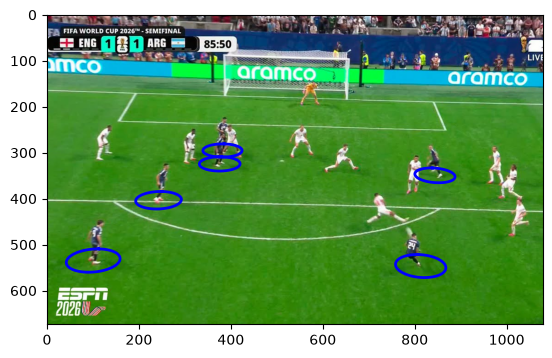

In [39]:
img_ej_4 = cv2.imread('futbol/test-gol-enzo.png')[:, :, ::-1]

paso_ej_4 = 2 * np.pi / 99
theta_ej_4 = np.arange(0, 2 * np.pi + paso_ej_4 / 2, paso_ej_4)

plt.imshow(img_ej_4)

jugadores_ej_4 = [j1, j2, j3, j4, j5, j6]

for j_ej_4 in jugadores_ej_4:
    pts_X_cancha_ej_4 = j_ej_4[0] + 1 * np.cos(theta_ej_4)
    pts_Y_cancha_ej_4 = j_ej_4[1] + 1 * np.sin(theta_ej_4)
    unos_ej_4 = np.ones(pts_X_cancha_ej_4.shape[0])

    circulo_cancha_ej_4 = np.array([pts_X_cancha_ej_4, pts_Y_cancha_ej_4, unos_ej_4])

    circulo_img_ej_4 = alc.arroba(H_enzo, circulo_cancha_ej_4)

    u_img_ej_4 = circulo_img_ej_4[0, :] / circulo_img_ej_4[2, :]
    v_img_ej_4 = circulo_img_ej_4[1, :] / circulo_img_ej_4[2, :]

    plt.plot(u_img_ej_4, v_img_ej_4, color='blue', linewidth=2)

plt.show()

c) Calcular la homografía de la changa de fútbol de la foto $\texttt{posibleoffside.jpg}$. 
    Trazar sobre la fotografía una recta sobre el pié del jugador del equipo defensor que defina si hay fuera de juego.
    

In [77]:
iP_ej_4_tiro_libre = np.array([733,316,731,759,1227,389,1363,577,1008,473,1474,387])
oP_ej_4_tiro_libre = np.array([[88.5,54.16],[88.5,13.84],[99.5,43.16],[99.5,24.84],[94,34],[105,43.16]])

Q_ej_4_tiro_libre = alc.obtenerQ2d(iP_ej_4_tiro_libre,oP_ej_4_tiro_libre)

H_ej_4_tiro_libre = alc.resolverDLT2D(Q_ej_4_tiro_libre)

Hinv_ej_4_tiro_libre = alc.inversa(H_ej_4_tiro_libre)

v_ej_4_tiro_libre = alc.arroba(Hinv_ej_4_tiro_libre, np.array([827,326,1]))
v_ej_4_tiro_libre = v_ej_4_tiro_libre/v_ej_4_tiro_libre[2]
print(f'Posición de jugador fuera de juego: {v_ej_4_tiro_libre[0:2]}')

Posición de jugador fuera de juego: [90.82916162 52.40493596]


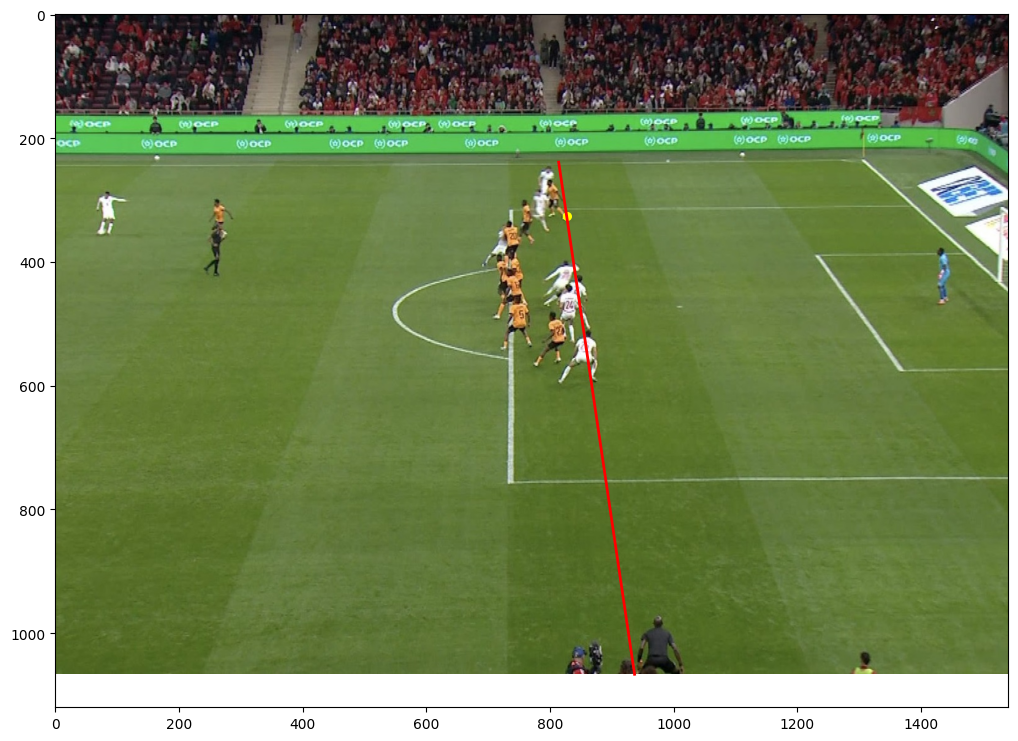

In [89]:
img_ej_4_c = cv2.imread('futbol/test-fuera-de-juego.png')[:, :, ::-1]
alto_ej_4_c, ancho_ej_4_c = img_ej_4_c.shape[0], img_ej_4_c.shape[1]

x_offside_ej_4_c = v_ej_4_tiro_libre[0]   

y_cancha_ej_4_c = np.arange(0, 68.1, 0.1)
puntos_cancha_ej_4_c = np.vstack([x_offside_ej_4_c + 0 * y_cancha_ej_4_c,   
                           y_cancha_ej_4_c,
                           np.ones(y_cancha_ej_4_c.shape[0])])

puntos_img_ej_4_c = alc.arroba(H_ej_4_tiro_libre, puntos_cancha_ej_4_c)
u_ej_4_c = puntos_img_ej_4_c[0, :] / puntos_img_ej_4_c[2, :]
v_img_ej_4_c = puntos_img_ej_4_c[1, :] / puntos_img_ej_4_c[2, :]

dentro_ej_4_c = (u_ej_4_c >= 0) & (u_ej_4_c < ancho_ej_4_c) & (v_img_ej_4_c >= 0) & (v_img_ej_4_c < alto_ej_4_c)

plt.figure(figsize=(14, 9))
plt.imshow(img_ej_4_c)
plt.plot(u_ej_4_c[dentro_ej_4_c], v_img_ej_4_c[dentro_ej_4_c], color='red', linewidth=2)
plt.scatter(827, 326, c='yellow', s=30)  
plt.show()

### Ejercicio 5 - Cruzando en rojo - Cálculo de velocidad

En este ejercicio decidimos considerar que estamos trabajando en un caso de puntos coplanares, más allá de la diferencia ínfima en altura de la calle al cordón de la vereda (0.1 m en la coordenada Z). El motivo por el cual se toma esta decisión y nos permite, de igual manera, resolver el problema es debido a que:
- Los puntos necesarios para resolver nuestro sistema, bajo el camino de tratarlo 3D, no son suficientes. Pero sí son suficientes para el caso 2D. El DLT 3D requiere de al menos 6 puntos no coplanares, y contamos con 5 puntos prácticamente planos. Pero con el caso 2D requerimos de 4 puntos únicamente.
- Las diferencias pequeñas en coordenadas provocan luego una matriz mal condicionada, por lo que sus operaciones y solución generan más distorsión que aproximación/estimación correcta.
- Los puntos que buscamos y con los que trabajamos se encuentran casi que a la misma altura, por lo que podemos pensar que buscamos puntos contenidos en un mismo plano. Dado que se encuentran en altura similares, esto no generara inconvenientes luego.

a) Calcular los parámetros intrínsecos de la cámara a partir de las diferentes vistas de la esquina y las coordenadas de los puntos en el archivo $\texttt{world\_img\_pts.csv}$

In [2]:
#Se realiza la lectura del archivo en un dataframe y se toma luego como un array para trabajar cómodamente en ello
ruta_csv_ej_5 = os.path.join('salguero', 'world_img_pts.csv')
df_ej_5 = pd.read_csv(ruta_csv_ej_5, sep=';')

array_df_ej_5 = np.array(df_ej_5)
objPts_ej_5 = array_df_ej_5[:,1:3] # cortando Z a propósito, si no lo veo, no existe 

Hlst_ej_5 = []

#Mediante este for logramos asociar a cada punto con un array que contiene las coordenadas correspondientes en píxeles
for k in range(4):
    indice_col_u = 4 + (2*k) 
    indice_col_v = 5 + (2*k)

    uv_k = array_df_ej_5[:, indice_col_u: indice_col_v + 1]

    imgPts_ej_5 = np.reshape(uv_k, -1)

    #Calculando Q para cada punto
    Q_ej_5 = alc.obtenerQ2d(imgPts_ej_5, objPts_ej_5)

    hatU_ej_5, hatSig_ej_5, hatV_ej_5 = alc.svd_reducida(Q_ej_5)

    #Y obteniendo H para luego sumar cada una a una lista y calcular A, por lo tanto luego calcular K
    Hk_ej_5 = np.reshape(hatV_ej_5[:,-1], (3, 3))
    Hlst_ej_5.append(Hk_ej_5)

A_ej_5 = alc.armarA(Hlst_ej_5)
K_ej_5 = alc.calcularMatrizK2D(A_ej_5)

print(f"\nK:\n{K_ej_5}")



K:
[[2.78278008e+03 1.35536578e+03 2.89090323e+02]
 [0.00000000e+00 2.13055733e+02 1.95627005e+02]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00]]


b) A partir de los puntos $\texttt{gs\_10\_09\_point\_correspondences\_v5.txt}$ calcular la pose de la cámara y reproyectar los puntos sobre la imagen $\texttt{img\_10\_18\_47\_351.jpg}$.

In [6]:
ruta_txt_ej_5 = os.path.join('salguero', 'gs_10_09_point_correspondences_v5.txt')
df_b_ej_5 = pd.read_csv(ruta_txt_ej_5, sep=r'\s+', header=None)
array_df_2_ej_5 = np.array(df_b_ej_5)

objPts_b_ej_5 = alc.transpuesta(array_df_2_ej_5[1:3, :])

uv_b_ej_5 = alc.transpuesta(array_df_2_ej_5[4:6, :])

# reshape para usar 
imgPts_b_ej_5 = np.reshape(uv_b_ej_5, -1)

Q_img_ej_5 = alc.obtenerQ2d(imgPts_b_ej_5, objPts_b_ej_5)
H_img_ej_5 = alc.resolverDLT2D(Q_img_ej_5)

R_pose_ej_5, t_pose_ej_5 = alc.obtenerPose2D(H_img_ej_5, K_ej_5)

print("R:\n", R_pose_ej_5)
print("\n t:\n", t_pose_ej_5)

R:
 [[ 0.97332983  0.45030938  0.04025384]
 [ 0.04182274 -0.08312263 -1.47474673]
 [-0.22556571  1.4107986  -0.09973891]]

 t:
 [-21.53276372  49.78253768  33.6156876 ]


In [4]:
print(alc.arroba(R_pose_ej_5,alc.transpuesta(R_pose_ej_5)))

[[ 1.15176988 -0.05608781  0.41173114]
 [-0.05608781  2.18353644  0.02038656]
 [ 0.41173114  0.02038656  2.05118045]]


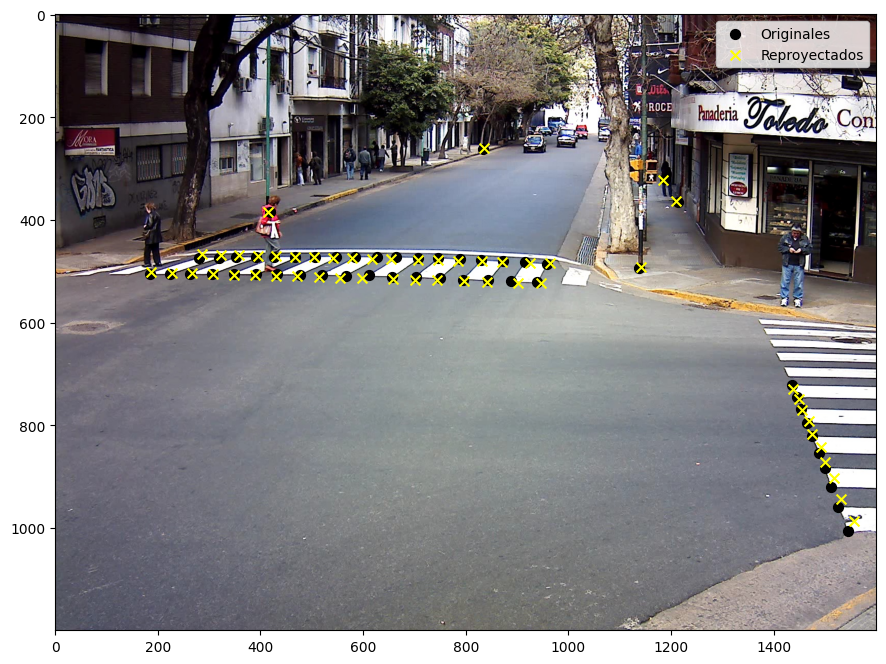

In [90]:

Rt_ej_5 = alc.armar_Rt(R_pose_ej_5, t_pose_ej_5)
M_ej_5 = alc.arroba(K_ej_5, Rt_ej_5)

N_ej_5 = array_df_2_ej_5.shape[1]
XYZ = array_df_2_ej_5[1:4, :]
unos = np.ones((1, N_ej_5))
P_homogeneos = np.vstack((XYZ, unos))

p_reproyectados = alc.arroba(M_ej_5, P_homogeneos)

u_proy = p_reproyectados[0, :] / p_reproyectados[2, :]
v_proy = p_reproyectados[1, :] / p_reproyectados[2, :]

ruta_img = os.path.join('salguero', 'img_10_18_47_351.jpg')
img_ej_5 = mpimg.imread(ruta_img)

plt.figure(figsize=(14, 8))
plt.imshow(img_ej_5)

plt.scatter(uv_b_ej_5[:, 0], uv_b_ej_5[:, 1], c='black', marker='o', s=50, label='Originales')

plt.scatter(u_proy, v_proy, c='Yellow', marker='x', s=50, label='Reproyectados')

plt.legend()
plt.show()


c) Calcular la velocidad de los dos primeros vehículos (taxi y camioneta) y de la señora de buzo rojo que cruza la calle. Graficar las velocidades en un plot temporal a lo largo de la secuencia.

In [82]:
carpeta = os.path.join('salguero', 'gs_dataset')
fotos = sorted([f for f in os.listdir(carpeta) if f.endswith('.jpg')])
tiempos_ej_5c = np.array([alc.tiempoDesdeNombre(f) for f in fotos])
tiempos_ej_5c = tiempos_ej_5c - tiempos_ej_5c[0]                           # que empiece en t = 0

# Píxeles marcados a mano 
# Señora de buzo rojo: punto medio entre los pies
idx_senora = [0, 5, 10, 15, 20, 25, 30, 35, 39, 45]
pix_senora = np.array([[420, 492], [505, 495], [557, 492], [648, 491], [714, 490],
                       [781, 485], [835, 484], [894, 484], [937, 484], [994, 484]])

# Taxi: rueda delantera del lado izquierdo de la imagen, donde toca el piso
idx_taxi = [30, 33, 36, 39, 42, 45]
pix_taxi = np.array([[685, 363], [637, 387], [570, 415],
                     [485, 452], [375, 502], [245, 557]])

# Camioneta: rueda delantera del lado izquierdo de la imagen, donde toca el piso
idx_camioneta = [30, 33, 36, 39, 42, 45]
pix_camioneta = np.array([[902, 328], [880, 340], [855, 360],
                          [820, 382], [780, 415], [735, 445]])

# 3) Píxel -> calle con H^{-1}
H_inv_ej_5c = alc.inversa(H_img_ej_5)

for nombre, pix, idx in [('Taxi', pix_taxi, idx_taxi),
                         ('Camioneta', pix_camioneta, idx_camioneta),
                         ('Señora', pix_senora, idx_senora)]:
    v, v_media = alc.calcularVelocidades(pix, idx, H_inv_ej_5c, tiempos_ej_5c)
    print(nombre)
    print('  velocidades entre fotos (km/h):', np.round(v * 3.6, 1))
    print('  velocidad media: %.1f km/h\n' % (v_media * 3.6))

Taxi
  velocidades entre fotos (km/h): [51.1 53.5 53.5 47.6 39.8]
  velocidad media: 49.0 km/h

Camioneta
  velocidades entre fotos (km/h): [41.8 64.9 56.6 58.4 42.7]
  velocidad media: 52.6 km/h

Señora
  velocidades entre fotos (km/h): [7.4 4.  4.9 5.9 6.5 4.2 4.6 4.8 3.9]
  velocidad media: 5.0 km/h



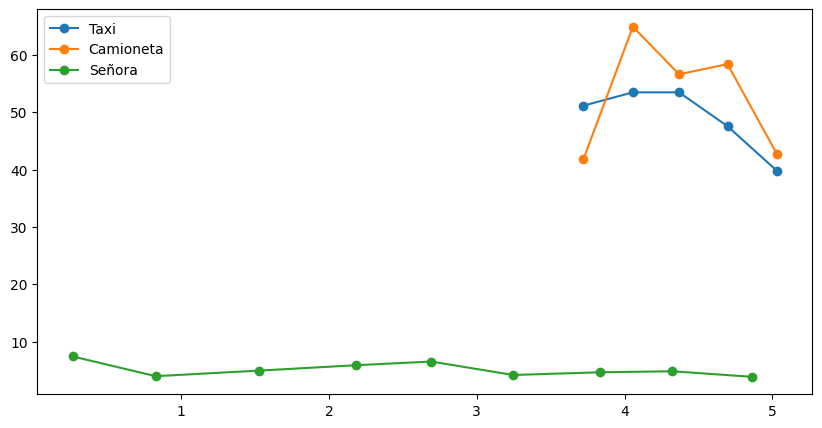

In [83]:
# Gráfico temporal de las velocidades: cada velocidad se ubica en el punto medio
# del intervalo de tiempo entre las dos fotos que la definen
plt.figure(figsize=(10, 5))
for nombre_ej_5c, pix_ej_5c, idx_ej_5c in [('Taxi', pix_taxi, idx_taxi),
                                           ('Camioneta', pix_camioneta, idx_camioneta),
                                           ('Señora', pix_senora, idx_senora)]:
    v_ej_5c, v_media_ej_5c = alc.calcularVelocidades(pix_ej_5c, idx_ej_5c, H_inv_ej_5c, tiempos_ej_5c)
    t_k_ej_5c = tiempos_ej_5c[np.array(idx_ej_5c)]
    t_medio_ej_5c = (t_k_ej_5c[1:] + t_k_ej_5c[:-1]) / 2
    plt.plot(t_medio_ej_5c, v_ej_5c * 3.6, marker='o', label=nombre_ej_5c)
plt.legend()
plt.show()

### Ejercicio 6 - Aterrizaje suave

a) Aplicar POSIT para encontrar la pose ($\mathbf{R}$ y $\mathbf{t}$) de la cámara del Drone a partir de la imagen $\texttt{row\_00248.png}$. La cámara tiene la matriz intrínseca $\mathbf{K}$. 

In [ ]:
# Definimos una matriz 5x2 con la coordenadas de los píxeles del centro y los extremos de la H de la imagen 
img_vecs = np.array([
    [525.0, 1003.0], # 0: Centro
    [402.0, 1097.0], # 1: Extremo sup izq
    [392.0, 945.0],  # 2: Extremo sup der
    [644.0, 912.0],  # 3: Extremo inf der
    [656.0, 1061.0]  # 4: Extremo inf izq
])

# Extraemos del csv la matriz de las coordenadas en el mundo real y limpiamos el df
ruta_obj = os.path.join('heli', 'object_points.csv')
df_obj = pd.read_csv(ruta_obj, sep=';', header=0)
obj_vecs = df_obj.iloc[:, 1:4].values

# Extraemos la matriz K directamente, acá no hay que limpiar nada porque ya está limpio
ruta_K = os.path.join('heli', 'K.csv')
df_K = pd.read_csv(ruta_K, sep=';', header=None)
K = df_K.values

"""
Con todo limpio y con los tipos de datos que necesita la función aplicarPOSIT(), 
la llamamos, la función recibirá los 5 puntos de la imagen (img_vecs) y del mundo real (obj_vecs), 
la matriz de calibración K, el límite máximo de iteraciones MaxIt y la tolerancia atol.
La función retornará la matriz de Rotación R (3x3) y de traslación t (3x1)
"""
R_final, t_final = alc.aplicarPOSIT(
    obj_vecs=obj_vecs, 
    img_vecs=img_vecs, 
    K=K, 
    MaxIt=100, 
    atol=1e-6
)

print(f"Matriz R:\n{R_final}")
print("\n")
print(f"Vector t:\n{t_final}")

la diferencia fue menor antes de terminar MaxIt, RMS_1 = 33.67897049141251, RMS_2 = 16.13878845120819
Matriz R:
[[-0.11038457 -0.89118188 -0.44001148]
 [-0.94388997  0.23264873 -0.23440627]
 [ 0.31126673  0.38944759 -0.86685846]]


Vector t:
[-0.57991907  0.76305141  3.72743228]


#### Conclusiones del item a):

aplicarPOSIT() convergió antes de llegar al límite de iteraciones y como los RMS_1 y RMS_2 tienen bastante diferencia, agarró la solución con menos promedio de error. 

El resultado de t ubica al dron a 4.423m de profundidad frente al lente y desplazado lateralmente en x (-0.688m) y en y (0.905m)

La distancia euclidiana entre el dron y el centro de la H sería $||t||_2$ = 4.57m

#### Siguiente item
b) o f) Estimar la matriz de rotación y traslación para ubicar al drone exactamente sobre la letra H y que la cámara la vea vertical (el punto blanco marca la parte superior izquierda)

Como las conclusiones del ítem anterior mostraron que el dron está desplazado e inclinado respecto del helipuerto, buscamos una pose objetivo ($R_{obj}$ y $t_{obj}$) que lo ubique centrado y perpendicular sobre la H.

#### 1. Posición del dron y traslación

Partiendo de la relación entre un punto en el sistema del mundo ($P_{real}$) y sus coordenadas en la cámara ($P_{cam}$):

$$P_{cam} = R P_{real} + t$$

Para hallar la posición del centro óptico de la cámara ($C$) expresada en el sistema de referencia del helipuerto, imponemos $P_{cam} = 0$ y despejamos $P_{real} = C$:

$$0 = R C + t$$
$$R C = -t$$
$$C = -R^{-1} t$$

Como $R$ es una matriz ortogonal ($R^{-1} = R^T$), obtenemos:

$$C = -R^T t$$

Aplicando esta fórmula tanto para la pose actual ($C_{actual}$) como para la objetivo ($C_{obj}$), ambas posiciones quedan expresadas en el mismo sistema de referencia (el del helipuerto) y podemos restarlas para obtener el desplazamiento necesario en $X$, $Y$ y $Z$:

$$\Delta C = C_{obj} - C_{actual}$$

#### 2. Rotación relativa ($dR$)

Tomando dos puntos del mundo $P_1$ y $P_2$ que definen un vector de dirección $v_w = P_2 - P_1$, sus proyecciones en el sistema de la cámara son:

$$P_{c,1} = R P_1 + t$$
$$P_{c,2} = R P_2 + t$$

Al restarlos para obtener el vector de dirección visto desde la cámara, la traslación $t$ se cancela:

$$v_c = P_{c,2} - P_{c,1} = (R P_2 + t) - (R P_1 + t) = R (P_2 - P_1) = R v_w$$

En nuestro caso particular, el mismo vector del mundo se expresa en la pose actual y en la objetivo como:

$$v_{actual} = R_{final} v_w$$
$$v_{obj} = R_{obj} v_w$$

La matriz de rotación relativa $dR$ debe transformar las coordenadas del vector desde la pose actual hacia la pose objetivo:

$$v_{obj} = dR v_{actual}$$

Sustituyendo:

$$R_{obj} v_w = dR (R_{final} v_w) = (dR R_{final}) v_w$$

Como esta igualdad vale para todo vector $v_w$, se cumple que $dR R_{final} = R_{obj}$. Despejando y conociendo la ortogonalidad de $R_{final}$ ($R_{final}^{-1} = R_{final}^T$), llegamos a:

$$dR = R_{obj} R_{final}^T$$

$R_{obj}$: Se fija como la matriz ${diag}(1, -1, -1)$ para que el eje óptico de la cámara apunte perpendicularmente hacia el piso con $Z = -1$ y el determinante se mantenga en $+1$

$t_{obj}$: Se toma como altura de referencia la distancia euclidiana actual entre la cámara y el centro de la H fijando $t_{obj}=(0,0,h)^T$ para centrar la H en el centro de la cámara

In [ ]:
# R objetico con la cámara mirando perpendicularmente hacia abajo
R_obj_ej_6 = np.array([[1.0, 0, 0], [0, -1.0, 0], [0, 0, -1.0]])

# t objetivo centrado en x e y, con z igual a la distancia 
# euclidiana entre el dron y el centro de la H
h_ej_6 = np.sqrt(np.sum(t_final**2))
t_obj_ej_6 = np.array([0, 0, h_ej_6])

# Posición actual (C = -R^t * t)
C_actual_ej_6 = (-1) * alc.arroba(alc.transpuesta(R_final), t_final)
# Posición objetivo (C = -R^t * t)
C_obj_ej_6 = (-1) * alc.arroba(alc.transpuesta(R_obj_ej_6), t_obj_ej_6)
# Delta_C final 
delta_C = C_obj_ej_6 - C_actual_ej_6

# La rotación relativa dR = R_obj * R_final^T
dR_ej_6 = alc.arroba(R_obj_ej_6, alc.transpuesta(R_final))

print("R_obj:\n", R_obj_ej_6)
print("t_obj:\n", t_obj_ej_6)

print("Traslación que tiene que hacer el drone:", delta_C)
print("Rotación que tiene que hacer: dR:\n", dR_ej_6)

R_obj:
 [[ 1.  0.  0.]
 [ 0. -1.  0.]
 [ 0.  0. -1.]]
t_obj:
 [0.         0.         3.84867574]
Traslación que tiene que hacer el drone: [0.50400321 2.14597583 0.69382654]
Rotación que tiene que hacer: dR:
 [[-0.11038457 -0.94388997  0.31126673]
 [ 0.89118188 -0.23264873 -0.38944759]
 [ 0.44001148  0.23440627  0.86685846]]


#### Conclusiones del ítem f)
Al pasar ambas poses al sistema del helipuerto, se obtiene que el dron debe desplazarse aproximadamente -0.65 m en X, -0.94 m en Y y 0.15 m en Z, aplicando también la rotación dR para corregir su inclinación.

---